# Table of Contents
- Exploratory Data Analsysis (very basic one)
    - Dataset exploration
    - Correlation matrix
- Linear Regression
    - Simple Linear Regressor
    - Standard Scaling + Linear Regressor
    - Normalizer + Linear Regressor
- Regularization
    - Ridge
    - Lasso
    - ElasticNet
- Polynomial Linear Regression
    - Simple Polynomial Linear Regressor
    - Ridge Linear Regressor
    - Lasso Linear Regressor
    - ElasticNet Linear Regressor
- Forward Feature Selection
- Backward Feature Selection

In [1]:
!pip install openml


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


## Dataset Description: CPU Activity (cpu_small)

The **CPU Activity (cpu_small)** dataset contains measurements of system activity from a multi-user Sun Sparcstation 20/712. It has **8,192 observations** and **13 columns**: 12 continuous input features and the continuous target `usr`.

#### Attribute Information
1. **lread** - Transfers per second between system memory and user memory.
2. **lwrite** - Transfers per second from system to user memory.
3. **scall** - Total system calls per second.
4. **sread** - System read calls per second.
5. **swrite** - System write calls per second.
6. **fork** - System fork calls per second.
7. **exec** - System exec calls per second.
8. **rchar** - Characters transferred per second by system reads.
9. **wchar** - Characters transferred per second by system writes.
10. **runqsz** - Process run queue size.
11. **freemem** - Memory pages available to user processes.
12. **freeswap** - Disk blocks available for swapping.
13. **usr** - CPU time (%) in user mode; this is the prediction target.

#### Regression Task
Predict `usr`, the percentage of CPU time spent in user mode.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openml

In [3]:
dataset = openml.datasets.get_dataset(562)  
X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute)

X.head()

,lread,lwrite,scall,sread,swrite,fork,exec,rchar,wchar,runqsz,freemem,freeswap
0,6.0,2.0,1036.0,103.0,114.0,1.00,1.00,172076.0,355965.0,2.0,6527.0,1851864.0
1,1.0,0.0,2165.0,205.0,101.0,0.40,1.20,43107.0,44139.0,3.0,130.0,1131931.0
2,62.0,77.0,3806.0,258.0,166.0,1.40,1.40,492142.0,268706.0,5.2,256.0,1314590.0
3,5.0,0.0,4721.0,256.0,177.0,0.99,2.58,524787.0,174964.0,1.0,233.0,972606.0
4,42.0,55.0,3949.0,249.0,244.0,2.60,4.60,197289.0,529200.0,3.4,331.0,1013805.0


In [4]:
df = pd.concat([X, y], axis=1)
df.head()

,lread,lwrite,scall,sread,swrite,fork,exec,rchar,wchar,runqsz,freemem,freeswap,usr
0,6.0,2.0,1036.0,103.0,114.0,1.00,1.00,172076.0,355965.0,2.0,6527.0,1851864.0,90
1,1.0,0.0,2165.0,205.0,101.0,0.40,1.20,43107.0,44139.0,3.0,130.0,1131931.0,88
2,62.0,77.0,3806.0,258.0,166.0,1.40,1.40,492142.0,268706.0,5.2,256.0,1314590.0,85
3,5.0,0.0,4721.0,256.0,177.0,0.99,2.58,524787.0,174964.0,1.0,233.0,972606.0,81
4,42.0,55.0,3949.0,249.0,244.0,2.60,4.60,197289.0,529200.0,3.4,331.0,1013805.0,79


In [5]:
from sklearn.datasets import fetch_openml

# Load the cpu_small dataset from OpenML
cpu_data = fetch_openml(data_id=562, as_frame=True)
df = cpu_data.frame
df.head()

/Users/timothyginting/Desktop/IntroToML/.venv/lib/python3.14/site-packages/sklearn/datasets/_openml.py:109: UserWarning: A network error occurred while downloading https://api.openml.org/api/v1/json/data/562. Retrying...
  warn(


URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1082)>

In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

#Let us understand the data-types for each attribute of the dataframe
df.info()

#Let us understand the fundamental statistics about the data and infer what it could inform us about the domain
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8192 entries, 0 to 8191
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   lread     8192 non-null   int64  
 1   lwrite    8192 non-null   int64  
 2   scall     8192 non-null   int64  
 3   sread     8192 non-null   int64  
 4   swrite    8192 non-null   int64  
 5   fork      8192 non-null   float64
 6   exec      8192 non-null   float64
 7   rchar     8192 non-null   int64  
 8   wchar     8192 non-null   int64  
 9   runqsz    8192 non-null   float64
 10  freemem   8192 non-null   int64  
 11  freeswap  8192 non-null   int64  
 12  usr       8192 non-null   int64  
dtypes: float64(3), int64(10)
memory usage: 832.1 KB


,lread,lwrite,scall,sread,swrite,fork,exec,rchar,wchar,runqsz,freemem,freeswap,usr
count,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00,8192.00
mean,19.56,13.11,2306.32,210.48,150.06,1.88,2.79,197013.67,95898.29,19.63,1763.46,1328125.96,83.97
std,53.35,29.89,1633.62,198.98,160.48,2.48,5.21,239480.83,140756.86,125.74,2482.10,422019.43,18.40
min,0.00,0.00,109.00,6.00,7.00,0.00,0.00,278.00,1498.00,1.00,55.00,2.00,0.00
25%,2.00,0.00,1012.00,86.00,63.00,0.40,0.20,33864.25,22935.50,1.20,231.00,1042623.50,81.00
50%,7.00,1.00,2051.50,166.00,117.00,0.80,1.20,124779.50,46620.00,2.00,579.00,1289289.50,89.00
75%,20.00,10.00,3317.25,279.00,185.00,2.20,2.80,267669.25,106148.00,3.00,2002.25,1730379.50,94.00
max,1845.00,575.00,12493.00,5318.00,5456.00,20.12,59.56,2526649.00,1801623.00,2823.00,12027.00,2243187.00,99.00


Based on the observed statistics for each attribute,we present a physical interpretation of the CPU Activity dataset attributes. These interpretations rely on the statistical tendencies (mean, standard deviation, and range) and suggest insights into typical system activity patterns on the monitored machine.

1. **lread (reads per second between system and user memory)**  
   - **Interpretation**: The mean of 19.56 and wide range up to 1845 indicates that memory read operations are generally low but occasionally spike significantly, likely due to intensive data access by user applications or services.

2. **lwrite (writes per second between system and user memory)**  
   - **Interpretation**: With a mean of 13.11 and a maximum of 575, write operations are slightly less frequent than read operations, but there are occasional bursts. This might reflect data modifications by user applications, such as file saving or updating operations.

3. **scall (system calls per second)**  
   - **Interpretation**: A high mean of 2306.32 and a wide range (109 to 12493) suggest continuous system interactions with user applications, as system calls mediate requests for services like file operations, network communication, and process control. The wide range indicates that system call demand varies greatly depending on user activity.

4. **sread (system read calls per second)**  
   - **Interpretation**: The mean of 210.48, along with peaks reaching 5318, shows that read operations are common, reflecting a mix of steady access and occasional high-demand phases, perhaps during data-intensive operations or processes that involve frequent data retrieval.

5. **swrite (system write calls per second)**  
   - **Interpretation**: Similar in pattern to `sread`, `swrite` has a lower mean of 150.06 but spikes up to 5456, indicating occasional high-demand write operations, possibly during logging, temporary data storage, or application outputs.

6. **fork (number of system fork calls per second)**  
   - **Interpretation**: The low mean of 1.88 and max of 20.12 show that process creation (forking) is infrequent but steady. However, there can be occasional surges, perhaps when new processes or sub-tasks are spawned, such as for complex or multi-threaded applications.

7. **exec (number of system exec calls per second)**  
   - **Interpretation**: With a mean of 2.79 and max of 59.56, the frequency of exec calls (executions of new processes) is generally low, suggesting that while new processes are initiated, they are typically fewer in number and less variable than other system activities.

8. **rchar (characters transferred per second by system read calls)**  
   - **Interpretation**: The mean of 197013.7 and max of over 2.5 million reflect a high volume of data being read by the system. This substantial data transfer indicates periods of intensive read operations, possibly during application loading, data processing, or file handling.

9. **wchar (characters transferred per second by system write calls)**  
   - **Interpretation**: Similar to `rchar`, the `wchar` metric with a mean of 95898.29 and a max of 1.8 million suggests a moderate level of write operations, likely driven by data output or storage operations. Peaks may occur during activities like log writing or data saving.

10. **runqsz (process run queue size)**  
    - **Interpretation**: A mean of 19.63 and max of 2823 show that the queue size for running processes varies widely, indicating periods of congestion where many processes await CPU time. This likely reflects the multi-user nature of the system, with potential for high process queuing during peak usage.

11. **freemem (available memory pages for user processes)**  
    - **Interpretation**: The average of 1763.46 with peaks up to 12027 suggests that the system generally has sufficient memory but may encounter occasional heavy memory usage, which could lead to reduced available memory during intensive tasks.

12. **freeswap (available disk blocks for swapping)**  
    - **Interpretation**: With a mean of 1.33 million and max of over 2.2 million, this metric shows a substantial amount of swap space, suggesting that while memory-intensive processes might consume RAM, the system has ample swap space to manage memory overflow and prevent slowdowns.

13. **usr (portion of CPU time in user mode)**  
    - **Interpretation**: The `usr` metric has a mean of 83.97% and ranges up to 100%, indicating that user-mode tasks dominate CPU activity. This reflects a user-driven workload where the CPU spends most of its time running applications or processes initiated by users rather than system tasks.

These interpretations provide insights into system behavior, identifying both steady trends and variability in resource demands across different attributes. The dataset's complexity suggests that while some activities are generally low, others exhibit spikes that could indicate peak user activity or intensive computational processes.

In [ ]:
#Let us check the total number of missing values in each column 
df.isnull().sum()

lread       0
lwrite      0
scall       0
sread       0
swrite      0
fork        0
exec        0
rchar       0
wchar       0
runqsz      0
freemem     0
freeswap    0
usr         0
dtype: int64

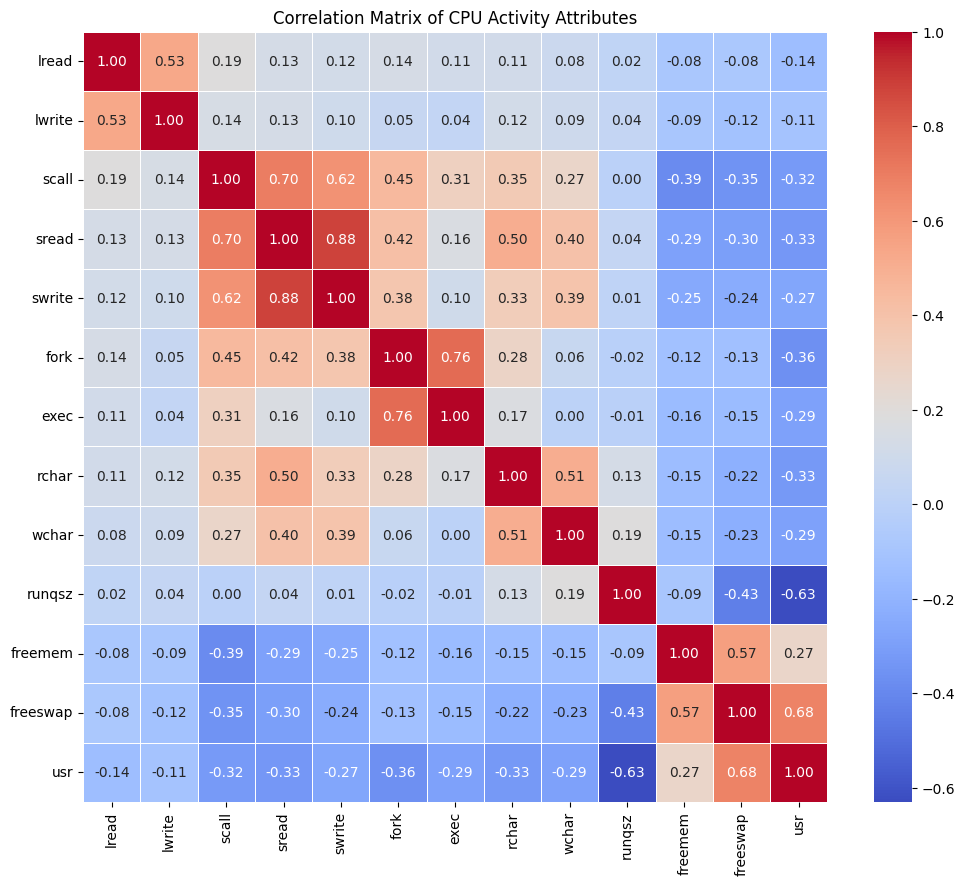

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
cor_matrix = df.corr()

# Plot the correlation matrix with values in the tiles
plt.figure(figsize=(12, 10))
sns.heatmap(cor_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix of CPU Activity Attributes")
plt.show()


#### Key Observations on Correlation Patterns

1. **High Positive Correlations**
   - **`sread` and `swrite` (0.88)**: System read and write calls per second are highly correlated, which makes sense as many operations that read data also perform write operations. This high correlation suggests that both attributes often increase or decrease together.
   - **`freemem` and `freeswap` (0.57)**: Available memory pages and swap disk blocks have a moderately high correlation. This could imply that when memory is free, there is also less demand on swap space, as swap is often used as an overflow when memory is low.

2. **Moderate Positive Correlations**
   - **`scall` with `sread` (0.70) and `swrite` (0.62)**: System calls per second correlate with read and write calls, indicating that read and write operations contribute significantly to system calls. This moderate correlation suggests that system call volume is partly driven by these data transfer activities.
   - **`fork` and `exec` (0.76)**: Fork and exec calls, which are related to process creation, are moderately correlated. This relationship is expected, as new processes (forks) often initiate execution requests (exec), reflecting the multi-step nature of process management.
   - **`usr` and `freemem` (0.27)**: User mode CPU time has a low-to-moderate positive correlation with available memory. This suggests that when memory is available, the CPU is more actively utilized in user mode, perhaps due to better resource availability for applications.

3. **Low or Insignificant Correlations**
   - Many attributes such as `lread`, `lwrite`, `rchar`, and `wchar` have relatively low correlations with other variables. These low correlations indicate that these operations do not strongly co-occur with other system activities, possibly reflecting more independent usage patterns or sporadic activity.

4. **Negative Correlations**
   - **`runqsz` and `usr` (-0.63)**: This negative correlation suggests an inverse relationship between process queue size and user CPU time, indicating that high process queueing generally leads to reduced CPU time available for user operations.
   - **`freemem` and `runqsz` (-0.43)**: Available memory pages and process queue size are negatively correlated, indicating that when memory availability is low, the queue size increases. This is likely because processes are stalled, awaiting memory resources.

#### Insights into System Resource Utilization

- **CPU Usage (usr) Patterns**: The `usr` attribute, representing the CPU’s time in user mode, is negatively correlated with `runqsz` (-0.63) and `fork` (-0.36), indicating that as more processes are queued or created, user mode CPU usage drops. This implies that CPU availability for user applications is compromised during high process contention.
  
- **Process Management (fork and exec)**: The strong correlation between `fork` and `exec` shows that these are related tasks, reinforcing their role in process creation and execution. However, they exhibit low correlations with attributes like `usr`, indicating that process management tasks do not heavily impact user mode CPU usage.

- **Memory and Swap Space Utilization**: The moderate positive correlation between `freemem` and `freeswap` (0.57) suggests that memory and swap space usage are somewhat aligned. When physical memory is available, swap space usage tends to be low, indicating efficient memory management. Low correlations with most other attributes indicate that memory usage does not strongly influence other CPU activities directly.

#### System Performance Implications

- The correlations indicate that system read and write operations (`sread` and `swrite`) are closely linked and play a central role in CPU activity. High values in both could signal I/O-intensive operations.
- High process queue size (`runqsz`) negatively affects user CPU time, indicating performance degradation under heavy loads.
- Memory availability (`freemem`) tends to support higher user CPU time, suggesting that memory constraints could be a bottleneck for CPU performance.


## Simple Linear Regression Model
Implement a Simple Linear Regression Model to Predict the User CPU Percentage Usage (`usr`)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Separate features and target variable
X = df.drop(columns=['usr'])
y = df['usr']

# Split the data into training and testing sets (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a linear regression model
linear_regressor = LinearRegression()
linear_regressor.fit(X_train, y_train)

# Make predictions
y_pred = linear_regressor.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Mean Squared Error: 86.0760622418185
R^2 Score: 0.712754595304175


Now, try scaling the dataset with a [Standard Scaler](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html#standardscaler):

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Separate features and target variable
X = df.drop(columns=['usr']) 
y = df['usr']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features (important for regression models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a linear regression model
linear_regressor = LinearRegression()
linear_regressor.fit(X_train_scaled, y_train)

# Make predictions
y_pred = linear_regressor.predict(X_test_scaled)

# Evaluate the model
mse_standard = mean_squared_error(y_test, y_pred)
r2_standard = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse_standard}")
print(f"R^2 Score: {r2_standard}")

Mean Squared Error: 86.07606224181694
R^2 Score: 0.7127545953041801


Why doesn't the standard scaler change the MSE?

... Write here the answer

Try now normalizing the dataset with [Normalizer](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html#normalizer):

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import Normalizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Separate features and target variable
X = df.drop(columns=['usr'])  # Assuming 'usr' is the target variable
y = df['usr']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features (important for regression models)
normalized = Normalizer()
X_train_standardized = normalized.fit_transform(X_train)
X_test_standardized = normalized.transform(X_test)

# Train a linear regression model
linear_regressor = LinearRegression()
linear_regressor.fit(X_train_standardized, y_train)

# Make predictions
y_pred = linear_regressor.predict(X_test_standardized)

# Evaluate the model
mse_normalizer = mean_squared_error(y_test, y_pred)
r2_normalizer = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse_normalizer}")
print(f"R^2 Score: {r2_normalizer}")


Mean Squared Error: 45.56358765734771
R^2 Score: 0.8479492342567919


**Normalizer** works across the values in each **row**. 

**StandardScaler** works down each **column**, adjusting each feature based on the dataset’s mean and spread.

Compare the mean squared error (MSE) of linear regression with no scaling, StandardScaler, and Normalizer. Show the results in a bar chart.

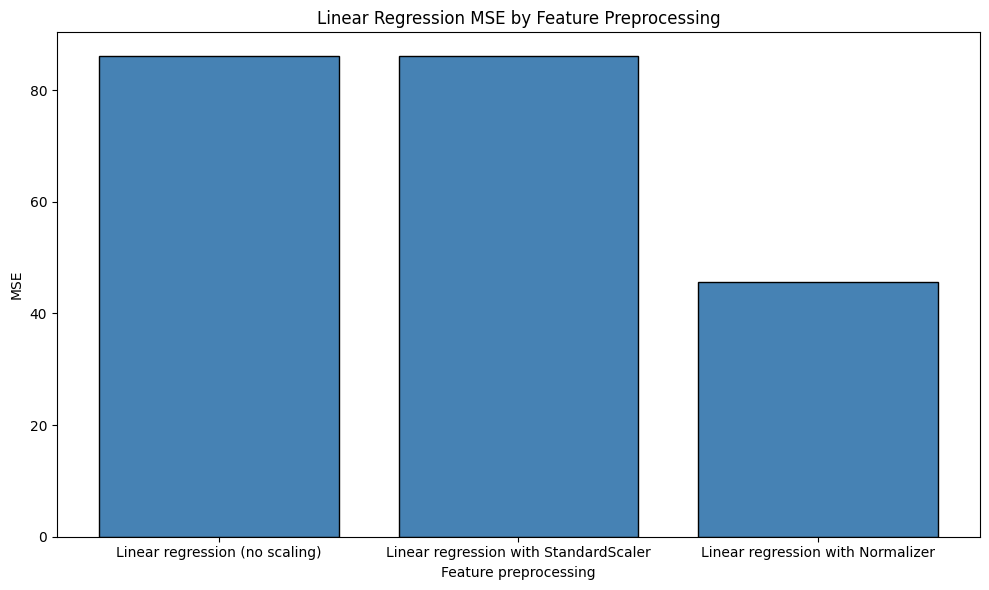

In [ ]:
# Collect all MSE values that were computed in previous cells
mse_type = [
    "Linear regression (no scaling)",
    "Linear regression with StandardScaler",
    "Linear regression with Normalizer"
]

mse_values = [mse, mse_standard, mse_normalizer]

# Create a bar chart of the MSEs
plt.figure(figsize=(10, 6))
# Compare the MSEs across feature preprocessing methods
plt.bar(mse_type, mse_values, color='steelblue', edgecolor='black')
plt.title('Linear Regression MSE by Feature Preprocessing')
plt.xlabel('Feature preprocessing')
plt.ylabel('MSE')
plt.tight_layout()
plt.show()



### Multiple Linear Regression with Ridge Penalty (Ridge Regression)

Ridge regression is an extension of multiple linear regression that includes a regularization term to control model complexity and reduce overfitting. In ridge regression, a penalty proportional to the **L2 norm** of the coefficients (sum of squared values of coefficients) is added to the loss function. This penalty term discourages the model from fitting noise in the data by shrinking the coefficients of less important features towards zero.

#### Ridge Regression Formula

For a dataset with $n$ samples and $p$ features, the linear regression model predicts the target $y$ as:

$$
\hat{y} = X \beta
$$

where:
- $X$ is the matrix of feature values ($n \times p$),
- $\beta$ is the vector of coefficients ($p \times 1$) to be learned,
- $\hat{y}$ is the vector of predicted values ($n \times 1$).

The objective of ridge regression is to minimize the following **cost function**:

$$
\mathcal{L} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p \beta_j^2
$$

where:
- $y_i$ is the true target value for sample $i$,
- $\hat{y}_i$ is the predicted target value for sample $i$,
- $\alpha \geq 0$ is the **regularization parameter** that controls the strength of the penalty (higher values increase regularization).

#### Explanation of Terms

1. **Sum of Squared Errors** $\left(\sum_{i=1}^n (y_i - \hat{y}_i)^2\right)$:
   - This term represents the standard residual sum of squares (RSS) for ordinary least squares regression. It measures the fit of the model to the data, aiming to minimize prediction error.

2. **Regularization Term** $\left(\alpha \sum_{j=1}^p \beta_j^2\right)$:
   - The second term penalizes large coefficients by adding the squared sum of coefficients, scaled by the regularization parameter $\alpha$.
   - If $\alpha = 0$, ridge regression reduces to ordinary least squares.
   - As $\alpha$ increases, the model becomes simpler by shrinking the coefficients, effectively reducing variance at the cost of slightly increased bias.

#### Impact of Regularization

- **Low $\alpha$**: When the regularization parameter is small, ridge regression behaves similarly to ordinary least squares, with a lower penalty on coefficient size.
- **High $\alpha$**: Higher values of $\alpha$ encourage the coefficients to shrink towards zero, making the model more resistant to overfitting. This is especially useful when dealing with multicollinearity (highly correlated features), as ridge regression reduces the impact of correlated features by shrinking their coefficients proportionally.

#### Interpretation and Use

- **Interpretation**: Ridge regression controls model complexity, helping to prevent overfitting in cases where features are highly correlated or when there are more features than samples.
- **Use Case**: Ridge regression is beneficial for datasets with multicollinearity or high-dimensional data where ordinary least squares regression would otherwise overfit.

[Documentation for Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)

In [ ]:
from sklearn.linear_model import Ridge
# Ridge Regression
ridge = Ridge(alpha=1)  # alpha is the regularization strength
ridge.fit(X_train_standardized, y_train)

# Predictions
y_pred_ridge = ridge.predict(X_test_standardized)

# Evaluation
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)
print("Ridge Regression - MSE:", mse_ridge, "R2:", r2_ridge)

Ridge Regression - MSE: 65.02404823483704 R2: 0.7830075102912606


### Multiple Linear Regression with Lasso Penalty (Lasso Regression)

Lasso regression is an extension of multiple linear regression that, like ridge regression, includes a regularization term to control model complexity and reduce overfitting. However, in lasso regression, a penalty proportional to the **L1 norm** of the coefficients (sum of the absolute values of coefficients) is added to the loss function. This L1 penalty can drive some coefficients exactly to zero, effectively performing feature selection by excluding less important features from the model.

#### Lasso Regression Formula

For a dataset with $n$ samples and $p$ features, the linear regression model predicts the target $y$ as:

$$
\hat{y} = X \beta
$$

where:
- $X$ is the matrix of feature values ($n \times p$),
- $\beta$ is the vector of coefficients ($p \times 1$) to be learned,
- $\hat{y}$ is the vector of predicted values ($n \times 1$).

The objective of lasso regression is to minimize the following **cost function**:

$$
\mathcal{L} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p |\beta_j|
$$

where:
- $y_i$ is the true target value for sample $i$,
- $\hat{y}_i$ is the predicted target value for sample $i$,
- $\alpha \geq 0$ is the **regularization parameter** that controls the strength of the penalty (higher values increase regularization).

#### Explanation of Terms

1. **Sum of Squared Errors** $\left(\sum_{i=1}^n (y_i - \hat{y}_i)^2\right)$:
   - This term represents the residual sum of squares (RSS) for ordinary least squares regression, measuring the fit of the model to the data by minimizing prediction error.

2. **Regularization Term** $\left(\alpha \sum_{j=1}^p |\beta_j|\right)$:
   - The second term penalizes large coefficients by adding the sum of their absolute values, scaled by the regularization parameter $\alpha$.
   - If $\alpha = 0$, lasso regression reduces to ordinary least squares.
   - As $\alpha$ increases, the model encourages more coefficients to shrink exactly to zero, effectively selecting only the most important features and making the model simpler.

#### Impact of Regularization

- **Low $\alpha$**: When the regularization parameter is small, lasso regression behaves similarly to ordinary least squares, with only minimal penalty on the coefficient size.
- **High $\alpha$**: Higher values of $\alpha$ force more coefficients to zero, performing feature selection and simplifying the model. This can be beneficial for high-dimensional datasets, where lasso automatically selects relevant features and excludes irrelevant ones.

#### Interpretation and Use

- **Interpretation**: Lasso regression not only controls model complexity but also performs feature selection by setting less important feature coefficients to zero. This makes lasso regression useful for sparse solutions, where many features may be irrelevant.
- **Use Case**: Lasso regression is particularly beneficial when the dataset has many features, some of which may not contribute meaningfully to the model. It is commonly used in cases where interpretability and feature selection are crucial, such as in high-dimensional or sparse data.

[Documentation for Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)

In [ ]:
from sklearn.linear_model import Lasso
# Lasso Regression
lasso = Lasso(alpha=0.1)  # alpha is the regularization strength
lasso.fit(X_train_standardized, y_train)


# Predictions
y_pred_lasso = lasso.predict(X_test_standardized)


# Evaluation
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)
print("Lasso Regression - MSE:", mse_lasso, "R2:", r2_lasso)

Lasso Regression - MSE: 65.81233540579977 R2: 0.7803769082220862


### Elastic Net

**Elastic Net** is a regularization technique that combines the penalties of both **ridge regression (L2 penalty)** and **lasso regression (L1 penalty)**. This combination allows Elastic Net to leverage the strengths of both ridge and lasso, effectively controlling model complexity, enhancing generalization, and performing feature selection. Elastic Net is particularly useful when dealing with high-dimensional data, where some features may be redundant or irrelevant.

#### Elastic Net Objective Function

In Elastic Net, the objective function to minimize is:

$$
\mathcal{L} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \left( \frac{1 - \lambda}{2} \sum_{j=1}^p \beta_j^2 + \lambda \sum_{j=1}^p |\beta_j| \right)
$$

where:
- $y_i$ is the true target value for sample $i$,
- $\hat{y}_i$ is the predicted target value for sample $i$,
- $\alpha$ is the regularization parameter controlling the overall strength of the penalty,
- $\lambda$ (often referred to as `l1_ratio`) controls the mix between L1 and L2 regularization.

#### Explanation of Terms

1. **L2 Penalty (Ridge)**: The term $\frac{1 - \lambda}{2} \sum_{j=1}^p \beta_j^2$ is the L2 penalty, which shrinks coefficients by adding the squared sum of their values. This penalty helps reduce multicollinearity by evenly distributing the weight across correlated features.

2. **L1 Penalty (Lasso)**: The term $\lambda \sum_{j=1}^p |\beta_j|$ is the L1 penalty, which performs feature selection by driving some coefficients exactly to zero. This excludes irrelevant features and produces a sparse model, improving interpretability.

#### Tuning the Hyperparameters ($\alpha$ and $\lambda$)

- **$\alpha$ (Regularization Strength)**: Controls the overall strength of regularization, with larger values applying more regularization and simplifying the model.
- **$\lambda$ (Mixing Parameter)**: Determines the balance between L1 and L2 penalties:
  - $\lambda = 1$ corresponds to pure lasso (only L1 penalty).
  - $\lambda = 0$ corresponds to pure ridge (only L2 penalty).
  - Intermediate values blend both penalties, balancing feature selection (L1) and multicollinearity handling (L2).

#### Interpretation and Use

- **Interpretation**: Elastic Net regularization provides a flexible approach that can handle both feature selection and coefficient shrinkage. It’s ideal for data with many features, some of which may be irrelevant, redundant, or highly correlated.
- **Use Case**: Elastic Net is particularly useful when dealing with high-dimensional data where multicollinearity or redundancy exists, and lasso alone would not perform well due to the strong correlations among features.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet

# Mixing in Pipeline to showcase how we can use different standardized methods when it is inconvenient to track the X_train_XYZ variables

# Elastic Net Regression
elastic_net = make_pipeline(
    StandardScaler(),
    ElasticNet(alpha=0.1, l1_ratio=0.5) # alpha is the regularization strength, l1_ratio is the mix between L1 and L2
)
# apply regularization
elastic_net.fit(X_train, y_train)

# Predictions
y_pred_elastic_net = elastic_net.predict(X_test)

# Evaluation
mse_elastic_net = mean_squared_error(y_test, y_pred_elastic_net)
r2_elastic_net = r2_score(y_test, y_pred_elastic_net)
print("Elastic Net Regression - MSE:", mse_elastic_net, "R2:", r2_elastic_net)

Elastic Net Regression - MSE: 85.17789498058711 R2: 0.7157518794702669


## Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Train a linear regression model
linear_regressor = LinearRegression()
linear_regressor.fit(X_train_poly, y_train)

# Make predictions
y_pred_poly = linear_regressor.predict(X_test_poly)

# Evaluate the model
mse_poly = mean_squared_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)
print("Polynomial Regression - MSE:", mse_poly, "R2:", r2_poly)

Polynomial Regression - MSE: 11.925373994764321 R2: 0.9602036990301477


Implement Ridge Regression with Polynomial Features:

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

poly_ridge = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1)
)

poly_ridge.fit(X_train, y_train)
y_pred_poly_ridge = poly_ridge.predict(X_test)

mse_poly_ridge = mean_squared_error(y_test, y_pred_poly_ridge)
r2_poly_ridge = r2_score(y_test, y_pred_poly_ridge)

print("Polynomial Ridge Regression - MSE:", mse_poly_ridge, "R2:", r2_poly_ridge)

Polynomial Ridge Regression - MSE: 12.150193029474584 R2: 0.9594534528766091


Implement the Lasso regression with polynomial features:

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

poly_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

poly_lasso.fit(X_train, y_train)
y_pred_poly_lasso = poly_lasso.predict(X_test)

mse_poly_lasso = mean_squared_error(y_test, y_pred_poly_lasso)
r2_poly_lasso = r2_score(y_test, y_pred_poly_lasso)

print("Polynomial Lasso Regression - MSE:", mse_poly_lasso, "R2:", r2_poly_lasso)

Polynomial Lasso Regression - MSE: 13.405144018183783 R2: 0.9552655416822926


Implement the Elastic Net regression model with polynomial features

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

poly_elastic_net = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
)

poly_elastic_net.fit(X_train, y_train)
y_pred_poly_elastic_net = poly_elastic_net.predict(X_test)

mse_poly_elastic_net = mean_squared_error(y_test, y_pred_poly_elastic_net)
r2_poly_elastic_net = r2_score(y_test, y_pred_poly_elastic_net)

print(
    "Polynomial Elastic Net Regression - MSE:",
    mse_poly_elastic_net,
    "R2:",
    r2_poly_elastic_net
)

Polynomial Elastic Net Regression - MSE: 14.077915844282227 R2: 0.9530204271821348


# Forward Feature Selection

## Introduction

Forward Feature Selection is a type of feature selection technique used in machine learning to select a subset of relevant features for model construction. This method is particularly useful when dealing with high-dimensional data, where many features may be irrelevant or redundant. The goal is to improve model performance by selecting only the most important features, thereby reducing overfitting and enhancing interpretability.

## How Forward Feature Selection Works

Forward Feature Selection is a greedy algorithm that starts with an empty model and iteratively adds features that improve the model the most. The process can be summarized in the following steps:

1. **Initialization**: Start with an empty set of selected features.
2. **Iteration**:
    - For each feature not yet selected, temporarily add it to the set of selected features.
    - Train a model using the current set of selected features.
    - Evaluate the model's performance using a chosen metric (e.g., R-squared, Mean Squared Error).
    - Select the feature that results in the best model performance and permanently add it to the set of selected features.
3. **Stopping Criterion**: Repeat the iteration until a stopping criterion is met. Common stopping criteria include:
    - A predefined number of features have been selected.
    - Adding more features does not significantly improve model performance.
    - Cross-validation performance starts to degrade, indicating potential overfitting.

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
import numpy as np

# Initialize variables for forward selection
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
print(X_train_poly.shape)
n_features = X_train_poly.shape[1]
selected_features = []
remaining_features = list(range(n_features))
best_mse = float('inf')
best_model = None

# Perform forward selection
while remaining_features:
    mse_with_feature = []

    # Test adding each remaining feature one at a time
    for feature in remaining_features:
        # Temporarily include the feature in the selected set
        temp_features = selected_features + [feature]
        
        # Train the Linear Regression model on the current set of features
        linear_regressor = LinearRegression()
        linear_regressor.fit(X_train_poly[:, temp_features], y_train)
        
        # Predict and evaluate on the test set
        y_pred = linear_regressor.predict(X_test_poly[:, temp_features])
        mse = mean_squared_error(y_test, y_pred)
        mse_with_feature.append((mse, feature))
    
    # Find the feature that resulted in the best improvement
    mse_with_feature.sort()
    best_new_mse, best_new_feature = mse_with_feature[0]

    # Check if this new feature improves the overall model performance
    if best_new_mse < best_mse:
        best_mse = best_new_mse
        selected_features.append(best_new_feature)
        remaining_features.remove(best_new_feature)
        best_model = linear_regressor
        print(f"Added feature {best_new_feature}, MSE: {best_mse}")
    else:
        # If no improvement, stop the forward selection
        break

# Final output
print(f"Best MSE: {best_mse}")
print(f"Selected features (indices in polynomial feature space): {selected_features}")
print(len(selected_features))

(6553, 90)
Added feature 11, MSE: 171.4004181522501
Added feature 89, MSE: 75.25981086646904
Added feature 38, MSE: 32.86448456441358
Added feature 44, MSE: 23.646198758687117
Added feature 74, MSE: 20.42370833302472
Added feature 79, MSE: 17.99545597685922
Added feature 88, MSE: 16.346996414256747
Added feature 68, MSE: 15.46276186672022
Added feature 8, MSE: 14.900863800203373
Added feature 0, MSE: 14.393222014524897
Added feature 86, MSE: 13.929145210139595
Added feature 87, MSE: 13.674803796687304
Added feature 3, MSE: 13.43514938383709
Added feature 45, MSE: 13.223922622325953
Added feature 78, MSE: 13.091163379825874
Added feature 76, MSE: 12.99585337599893
Added feature 10, MSE: 12.91669190990149
Added feature 4, MSE: 12.861733105712178
Added feature 69, MSE: 12.808968325067045
Added feature 63, MSE: 12.763589103986627
Added feature 62, MSE: 12.689907164450434
Added feature 85, MSE: 12.657231062625867
Added feature 51, MSE: 12.537887545802132
Added feature 7, MSE: 12.46287614499

# Backward Feature Selection

## Introduction

Backward Feature Selection, also known as backward elimination, is a feature selection technique used in machine learning to identify the most relevant features for model construction. This method is particularly useful for high-dimensional data, where many features may be irrelevant or redundant. The goal is to improve model performance by removing less important features, thereby reducing overfitting and enhancing interpretability.

## How Backward Feature Selection Works

Backward Feature Selection is a greedy algorithm that starts with all features and iteratively removes the least significant features. The process can be summarized in the following steps:

1. **Initialization**: Start with the full set of features.
2. **Iteration**:
    - Train a model using the current set of features.
    - Evaluate the model's performance using a chosen metric (e.g., R-squared, Mean Squared Error).
    - Identify the least significant feature based on a criterion (e.g., p-value, feature importance).
    - Remove the least significant feature from the set.
3. **Stopping Criterion**: Repeat the iteration until a stopping criterion is met. Common stopping criteria include:
    - A predefined number of features have been removed.
    - Removing more features does not significantly degrade model performance.
    - Cross-validation performance starts to degrade, indicating potential underfitting.

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Initialize variables to store the best model and features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
best_features = list(range(X_train_poly.shape[1]))  # Start with all polynomial features
best_mse = float('inf')
selected_features = best_features[:]
print(X_train_poly.shape)

# Iteratively remove features based on the absolute values of coefficients
for _ in range(len(best_features) - 1):  # Stop when we have only one feature left
    # Train Polynomial Linear Regression on the current set of features
    linear_regressor = LinearRegression()
    linear_regressor.fit(X_train_poly[:, selected_features], y_train)

    # Predict and evaluate on the test set
    y_pred = linear_regressor.predict(X_test_poly[:, selected_features])
    mse = mean_squared_error(y_test, y_pred)
    print(f"Features left: {len(selected_features)}, MSE: {mse}")

    # Track the best model based on test MSE
    if mse < best_mse:
        best_mse = mse
        best_model = linear_regressor
        best_features = selected_features[:]

    # Get the coefficients of the model and find the least important feature
    coefs = linear_regressor.coef_
    least_important_feature = selected_features[np.argmin(np.abs(coefs))]

    # Remove the least important feature
    selected_features.remove(least_important_feature)

# Output the best model and features selected
print(f"Best MSE: {best_mse}")
print(f"Selected features (indices in polynomial feature space): {best_features}")
print(len(best_features))

(6553, 90)
Features left: 90, MSE: 12.125113436600392
Features left: 89, MSE: 12.100423669114557
Features left: 88, MSE: 12.108131086387788
Features left: 87, MSE: 12.106932294113607
Features left: 86, MSE: 12.102607268303416
Features left: 85, MSE: 11.993803687164448
Features left: 84, MSE: 11.99344756173262
Features left: 83, MSE: 38.429818240018776
Features left: 82, MSE: 38.42853384178026
Features left: 81, MSE: 38.43231343315263
Features left: 80, MSE: 38.42916306290478
Features left: 79, MSE: 38.42676487231248
Features left: 78, MSE: 38.90909071920701
Features left: 77, MSE: 38.91112091326513
Features left: 76, MSE: 38.926493335595836
Features left: 75, MSE: 40.828863927538904
Features left: 74, MSE: 40.821758039142374
Features left: 73, MSE: 40.96525470307891
Features left: 72, MSE: 40.887162235802236
Features left: 71, MSE: 40.93820435068769
Features left: 70, MSE: 40.6827659827567
Features left: 69, MSE: 40.989060157309034
Features left: 68, MSE: 40.98942880324183
Features lef